In [2]:
path_to_dodem = '/Users/jmdunca2/do-dem/'
from sys import path as sys_path
sys_path.append(path_to_dodem+'/dodem/')

import HARP_and_age as haa
import all_nu_analysis as ana

import pickle
import importlib

import numpy as np
from matplotlib import pyplot as plt
from astropy import units as u

from astropy.visualization import quantity_support
quantity_support()

with open('/Users/jmdunca2/do-dem/reference_files/all_targets_postghost_postshut.pickle', 'rb') as f:
    all_targets = pickle.load(f)
    

In [3]:
print(all_targets.keys())

dict_keys(['01-nov-14_1', '01-nov-14_2', '11-dec-14', '19-feb-16', '22-apr-16_1', '22-apr-16_2', '26-jul-16_1', '27-jul-16_1', '26-jul-16_2', '10-oct-17', '29-may-18_1', '29-may-18_2', '07-sep-18', '09-sep-18', '10-sep-18', '12-apr-19', '13-apr-19', '29-jan-20', '06-jun-20', '07-jun-20', '08-jun-20', '09-jun-20', '08-jan-21', '14-jan-21', '20-jan-21', '29-apr-21', '03-may-21_1', '03-may-21_2', '30-jul-21_1', '30-jul-21_2', '17-nov-21_1', '19-nov-21', '20-nov-21', '22-nov-21_1', '22-nov-21_2', '03-jun-22_1', '03-jun-22_2', '06-sep-22', '09-dec-22', '17-nov-21_2', '21-nov-21', '30-jan-20', '20-jul-21', '24-feb-22', '25-feb-22', '27-feb-22', '18-mar-23_2', '11-dec-22_2'])


In [36]:
for kk in all_targets.keys():
    print(kk)
    files = all_targets[kk]['res_file_dict(s)'][0]['quiet files all-inst']
    for f_ in files:
        with open(f_, 'rb') as f:
            data = pickle.load(f)
    
        #print(data.keys())
        #print(data['ts'])
        #print(10**(data['ts'])) #Temperature bin centers, K 
        #dT = log10(T+dTlog) 
        
        dT_ = 10**(data['ts'])*(10**dT-1)
        #print(dT)
        #print(10**(data['ts_']))
    
        #print(np.max(data['DEM']))
        dem_units = data['DEM']/dT_
        #plt.plot(dem_units)
        print(data['time_interval'][0].strftime('%H-%M-%S'), np.max(data['DEM']), np.max(dem_units))
    print('')

    

01-nov-14_1
21-34-45 3.760394085518881e+26 1.6360924547034519e+21
21-41-55 3.775916326571271e+26 1.6428459547059387e+21

01-nov-14_2

11-dec-14
18-38-55 3.388116123601422e+26 1.474119759636443e+21

19-feb-16
18-54-50 2.3160899627335166e+26 1.0076968600273263e+21
20-31-30 2.4056357082547147e+26 9.840593232081935e+20
20-34-35 2.411744422318095e+26 9.858709573214076e+20
20-37-45 2.4061657273460354e+26 9.842059108222156e+20
20-41-15 2.414081644624892e+26 9.853492600064638e+20
23-44-55 2.7822564735524413e+26 1.0845308901598424e+21

22-apr-16_1

22-apr-16_2
18-47-45 1.6586485930539154e+26 7.216537379819739e+20
20-24-30 1.6964702955677252e+26 7.381094074409754e+20
22-01-10 1.5179700024470473e+26 6.604465412372068e+20
22-06-25 1.530761545724524e+26 6.66011954586006e+20
22-12-45 1.5275562387400848e+26 6.646173724084506e+20
22-18-30 1.5425958911287525e+26 6.711609051432828e+20

26-jul-16_1
20-11-35 1.584940042134522e+26 6.924284188876808e+20
20-59-35 1.362611121720354e+26 6.896481134375873e+20



In [8]:
files = all_targets['11-dec-22_2']['res_file_dict(s)'][0]['quiet files all-inst']

mlogt70 - DEM temperature bin centers
temps - response function temperature array

mkt = np.array(mlogt70)
mkt_ = np.array(temps)


'ts': mkt
'ts_': mkt_


dT = T2-T1
dTlog = T2log - T1log

T1log = log10(T1)
T2log = T1log+dTlog

T1 = 10**(T1log)
T2 = 10**(T2log) = 10**(T1log+dTlog)

dT = 10**(T1log+dTlog) - T1
    =10**(log10(T1))10**(dTlog) - T1
    =T1(10**dTlog - 1)


In [22]:
(10**7.225)-(10**7.175)

1825683.6202812623

5.8463878447100566e+26
2.2670552458040482e+21

5.983391947241246e+26
2.3201813601826971e+21

5.892543588118688e+26
2.284953069725053e+21

5.7896350543951844e+26
2.2450482024099354e+21

5.79720242764659e+26
2.2479826045882102e+21

5.779313061487478e+26
2.2410456406931753e+21



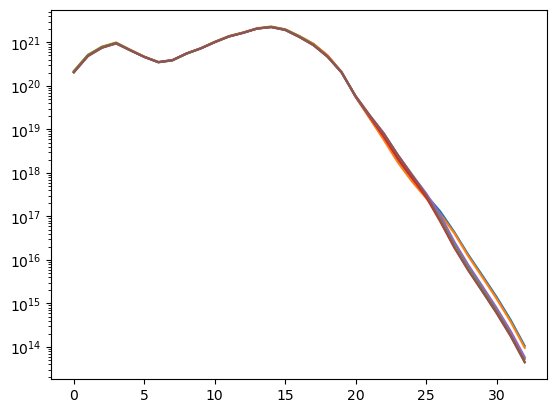

In [29]:
dT=0.05

for f_ in files:
    with open(f_, 'rb') as f:
        data = pickle.load(f)

    #print(data.keys())
    #print(data['ts'])
    #print(10**(data['ts'])) #Temperature bin centers, K 
    #dT = log10(T+dTlog) 
    
    dT_ = 10**(data['ts'])*(10**dT-1)
    #print(dT)
    #print(10**(data['ts_']))

    print(np.max(data['DEM']))
    dem_units = data['DEM']/dT_
    plt.plot(dem_units)
    print(np.max(dem_units))
    print('')

plt.yscale('log')